In [113]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score
)

df = pd.read_csv('course_lead_scoring_2026.csv')


In [114]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [115]:
df.shape

(5000, 9)

In [116]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [117]:
df.isnull().sum()

,0
lead_source,148
industry,240
employment_status,194
location,208
annual_income,369
number_of_courses_viewed,0
interaction_count,0
lead_score,35
converted,0


In [118]:
target = "converted"

categorical = list(df.select_dtypes(include="object").columns)

numerical = [c for c in df.select_dtypes(exclude="object").columns
    if c != target
]

df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

In [119]:
df.isnull().sum()

,0
lead_source,0
industry,0
employment_status,0
location,0
annual_income,0
number_of_courses_viewed,0
interaction_count,0
lead_score,0
converted,0


In [120]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [121]:
y_train = df_train['converted'].values
df_train = df_train.drop(columns=['converted'])

y_val = df_val['converted'].values
df_val = df_val.drop(columns=['converted'])

y_full_train = df_full_train['converted'].values
df_full_train = df_full_train.drop(columns=['converted'])

## Question 1: ROC AUC feature importance
ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

- For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
- Use the training dataset for that
If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. -df_train['balance'])

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- lead_score
- number_of_courses_viewed
- interaction_count
- annual_income

In [122]:
from sklearn.metrics import roc_auc_score

for col in [
    'lead_score',
    'number_of_courses_viewed',
    'interaction_count',
    'annual_income'
]:
    auc = roc_auc_score(y_train, df_train[col])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])

    print(col, round(auc, 3))

lead_score 0.788
number_of_courses_viewed 0.723
interaction_count 0.765
annual_income 0.608


## Question 2: Training the model
Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:

  LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
  
What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832

In [123]:
train_dicts = df_train.to_dict(orient="records")
val_dicts = df_val.to_dict(orient="records")

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [124]:
model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)

round(auc, 3)

np.float64(0.732)

## Question 3: Precision and Recall
Now let's compute precision and recall for our model.

- Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
- For each threshold, compute precision and recall
- Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

- 0.43
- 0.63
- 0.73
- 0.83

In [125]:
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0, 1.01, 0.01)

precisions = []
recalls = []

for t in thresholds:
    y_pred_binary = (y_pred >= t).astype(int)

    precisions.append(
        precision_score(y_val, y_pred_binary, zero_division=0)
    )

    recalls.append(
        recall_score(y_val, y_pred_binary, zero_division=0)
    )

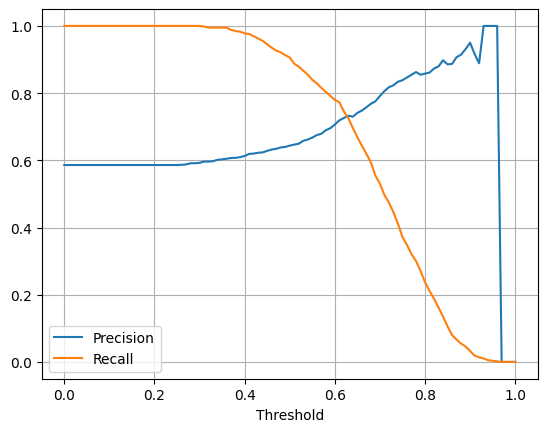

In [126]:
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')

plt.xlabel('Threshold')
plt.legend()
plt.grid()
plt.show()

In [127]:
differences = np.abs(
    np.array(precisions) - np.array(recalls)
)

for i in range(len(thresholds)):
    if precisions[i] == 0 and recalls[i] == 0:
        differences[i] = np.inf

best_index = np.argmin(differences)

print('Threshold:', thresholds[best_index])
print('Precision:', precisions[best_index])
print('Recall:', recalls[best_index])

Threshold: 0.63
Precision: 0.7327586206896551
Recall: 0.7252559726962458


## Question 4: F1 score
Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

F1=2(⋅P⋅R/P+R)

Where P is precision and R is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81

In [128]:
f1_scores = []

for p, r in zip(precisions, recalls):
    if p + r == 0:
        f1 = 0
    else:
        f1 = 2 * p * r / (p + r)

    f1_scores.append(f1)

best_index = np.argmax(f1_scores)

print('Best threshold:', thresholds[best_index])
print('Best F1 score:', f1_scores[best_index])
print('Precision:', precisions[best_index])
print('Recall:', recalls[best_index])

Best threshold: 0.41000000000000003
Best F1 score: 0.7576158940397352
Precision: 0.6190476190476191
Recall: 0.9761092150170648


## Question5: 5-Fold CV
Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

KFold(n_splits=5, shuffle=True, random_state=1)

- Iterate over different folds of df_full_train
- Split the data into train and validation
- Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
- Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060

In [129]:
from sklearn.model_selection import KFold
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]

    y_train_fold = y_full_train[train_idx]
    y_val_fold = y_full_train[val_idx]

    train_dicts = df_train_fold.to_dict(orient='records')
    val_dicts = df_val_fold.to_dict(orient='records')

    dv = DictVectorizer(sparse=False)

    X_train_fold = dv.fit_transform(train_dicts)
    X_val_fold = dv.transform(val_dicts)

    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )

    model.fit(X_train_fold, y_train_fold)

    y_pred_fold = model.predict_proba(X_val_fold)[:, 1]

    auc = roc_auc_score(y_val_fold, y_pred_fold)
    scores.append(auc)

print('AUC scores:', scores)
print('Mean AUC:', np.mean(scores))
print('Standard deviation:', np.std(scores))

AUC scores: [np.float64(0.7305601027122453), np.float64(0.7295726148196622), np.float64(0.7363428071259397), np.float64(0.7412454717957564), np.float64(0.7209138590326581)]
Mean AUC: 0.7317269710972524
Standard deviation: 0.006853233151022138


## Question 6: Hyperparameter Tuning
Now let's use 5-Fold cross-validation to find the best parameter C

- Iterate over the following C values: [0.000001, 0.001, 1]
- Initialize KFold with the same parameters as previously
- Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)
- Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).

Which C leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest C.

In [130]:
for C in [0.000001, 0.001, 1]:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]

        y_train_fold = y_full_train[train_idx]
        y_val_fold = y_full_train[val_idx]

        train_dicts = df_train_fold.to_dict(orient='records')
        val_dicts = df_val_fold.to_dict(orient='records')

        dv = DictVectorizer(sparse=False)

        X_train_fold = dv.fit_transform(train_dicts)
        X_val_fold = dv.transform(val_dicts)

        model = LogisticRegression(
            solver='liblinear',
            C=C,
            max_iter=1000
        )

        model.fit(X_train_fold, y_train_fold)

        y_pred_fold = model.predict_proba(X_val_fold)[:, 1]

        auc = roc_auc_score(y_val_fold, y_pred_fold)
        scores.append(auc)

    print(
        'C:', C,
        'Mean AUC:', round(np.mean(scores), 4),
        'Std:', round(np.std(scores), 4)
    )

C: 1e-06 Mean AUC: 0.6167 Std: 0.0187
C: 0.001 Mean AUC: 0.7492 Std: 0.01
C: 1 Mean AUC: 0.7317 Std: 0.0069
